# Pump it Up：坦桑尼亚水泵状态预测
## 课程作业参考样例

本例覆盖任务定义、数据质量分析、特征工程、分层验证、模型比较、错误分析及预测文件生成。
使用 **DrivenData 原始公开数据**，所有指标来自本项目在服务器 21 的实际运行。
线上排行榜成绩未获取，不能把本地验证准确率写成线上成绩。

目标 `status_group` 的三类为 `functional`（正常）、`functional needs repair`（运行但需维修）、
`non functional`（无法运行）。[官方题目与字段说明](https://www.drivendata.org/competitions/7/pump-it-up-data-mining-the-water-table/page/25/)

学习时建议先逐节理解，再按课程要求自行调整模型与讨论；报告中的参数和结果可由配套脚本复现。

## 1. 环境、路径与数据来源

在项目目录运行 `python -m pip install -r requirements.txt`，然后打开本 Notebook。
首次缺少数据时会从 DrivenData 自有公开 S3 地址下载三份数据 CSV，
并从 DrivenData 官方代码仓库取得提交模板，保留 SHA-256 与来源清单。
特征表与标签表用 `id` 对齐；不假定它们的原始行顺序相同。

In [1]:
from pathlib import Path
import json, sys, subprocess
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
ROOT = Path.cwd()
if not (ROOT / 'pump_model.py').exists() and (ROOT / 'pump_it_up_reference').exists():
    ROOT = ROOT / 'pump_it_up_reference'
sys.path.insert(0, str(ROOT))
from pump_model import (load_data, PumpFeatures, build_models, write_submission, LABELS, SEED)
from download_data import download
OUT = ROOT / 'results'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
required_data = ['train_values.csv', 'train_labels.csv', 'test_values.csv', 'SubmissionFormat.csv']
if not all((ROOT / 'data/raw' / name).exists() for name in required_data):
    download()
X, y, X_test = load_data(ROOT / 'data/raw')
print('训练特征：', X.shape, '标签：', y.shape, '无标签测试特征：', X_test.shape)
print('原始预测字段数（不含 id）：', X.shape[1] - 1)
display(X.head(3))

训练特征： (59400, 40) 标签： (59400,) 无标签测试特征： (14850, 40)
原始预测字段数（不含 id）： 39


,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,payment_type,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,...,annually,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,...,never pay,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,...,per bucket,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe


## 2. 先分离验证集，再分析训练部分

按类别分层，80% 用于开发，20% 保留作最终验证；固定随机种子 42。
候选模型只按开发集内部三折交叉验证的平均 Accuracy 排名。
验证集的中位数、类别频率及标签均不用于拟合或选参。
以下含标签的数据探索仅使用开发集，避免基于最终验证集反复改特征。

开发集： 47520 最终验证集： 11880


,count,proportion
status_group,,
functional,25807,0.543077
functional needs repair,3454,0.072685
non functional,18259,0.384238


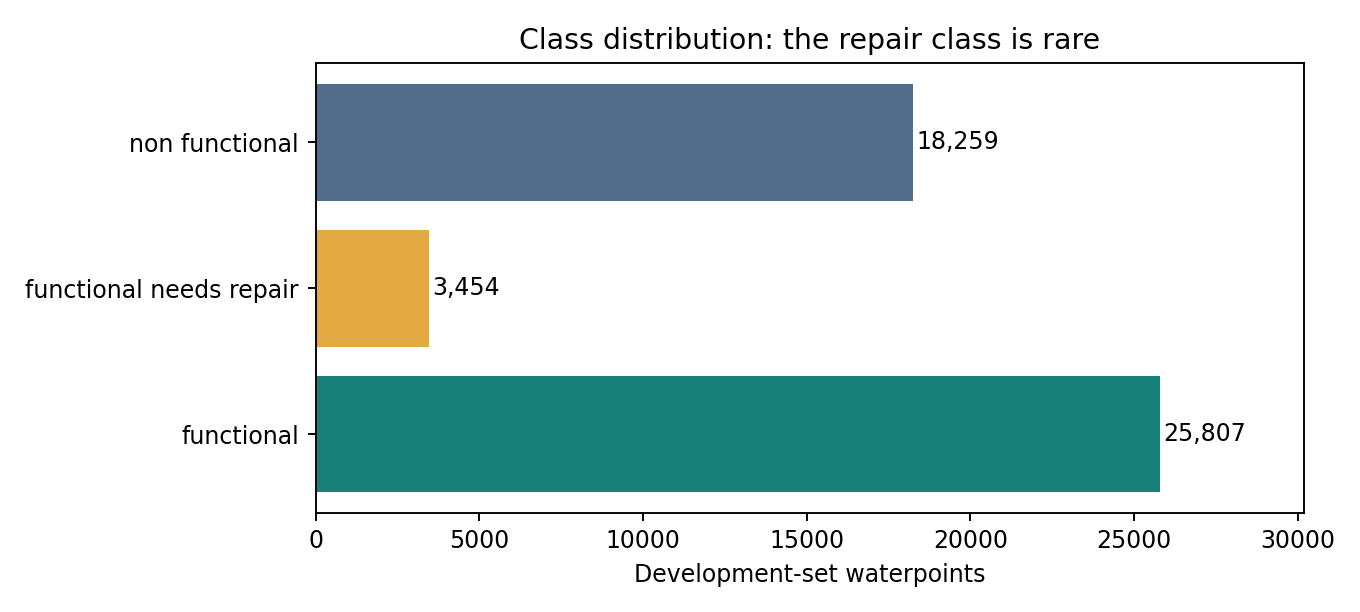

In [2]:
train_idx, valid_idx = train_test_split(np.arange(len(X)), test_size=0.2,
                                       stratify=y, random_state=SEED)
X_train, X_valid = X.iloc[train_idx].copy(), X.iloc[valid_idx].copy()
y_train, y_valid = y.iloc[train_idx].copy(), y.iloc[valid_idx].copy()
print('开发集：', len(train_idx), '最终验证集：', len(valid_idx))
counts = y_train.value_counts().reindex(LABELS)
distribution = pd.DataFrame({'count': counts, 'proportion': counts / len(y_train)})
display(distribution)
distribution.to_csv(OUT / 'class_distribution_development.csv')
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(LABELS, counts, color=['#178078', '#e3aa43', '#536c8a'])
ax.set_xlabel('Development-set waterpoints')
ax.set_title('Class distribution: the repair class is rare')
for i, value in enumerate(counts): ax.text(value + 100, i, f'{value:,}', va='center')
ax.set_xlim(0, counts.max() * 1.17)
fig.tight_layout(); fig.savefig(FIG / 'class_distribution.png', dpi=170)
plt.close(fig); display(Image(filename=str(FIG / 'class_distribution.png')))

类别不均衡时，全预测多数类也能得到看似不低的 Accuracy。
因此除了 Accuracy，本例同时报告 Macro-F1 与各类别 Recall，尤其观察需维修类别。
Macro-F1 是三类 F1 的等权平均，不等于总体准确率。

In [3]:
quality = pd.DataFrame({'dtype': X_train.dtypes.astype(str),
                        'missing_count': X_train.isna().sum(),
                        'missing_rate': X_train.isna().mean(),
                        'unique_values': X_train.nunique(dropna=True)})
quality.sort_values('missing_rate', ascending=False).to_csv(OUT / 'data_quality.csv')
display(quality.sort_values('missing_rate', ascending=False).head(12))
zero_counts = {c: int((X_train[c] == 0).sum()) for c in
               ['construction_year', 'population', 'gps_height', 'longitude', 'amount_tsh']}
print('部分字段的零值数量：', zero_counts)
print('注意：零值与缺失值不同，不能把每一列的 0 都统一替换为缺失。')

,dtype,missing_count,missing_rate,unique_values
scheme_name,object,23050,0.485059,2562
scheme_management,object,3129,0.065846,11
installer,object,2917,0.061385,1929
funder,object,2906,0.061153,1715
public_meeting,object,2644,0.055640,2
permit,object,2443,0.051410,2
subvillage,object,286,0.006019,17231
wpt_name,object,2,0.000042,30660
latitude,float64,0,0.000000,46027
longitude,float64,0,0.000000,46029


部分字段的零值数量： {'construction_year': 16517, 'population': 17066, 'gps_height': 16305, 'longitude': 1442, 'amount_tsh': 33265}
注意：零值与缺失值不同，不能把每一列的 0 都统一替换为缺失。


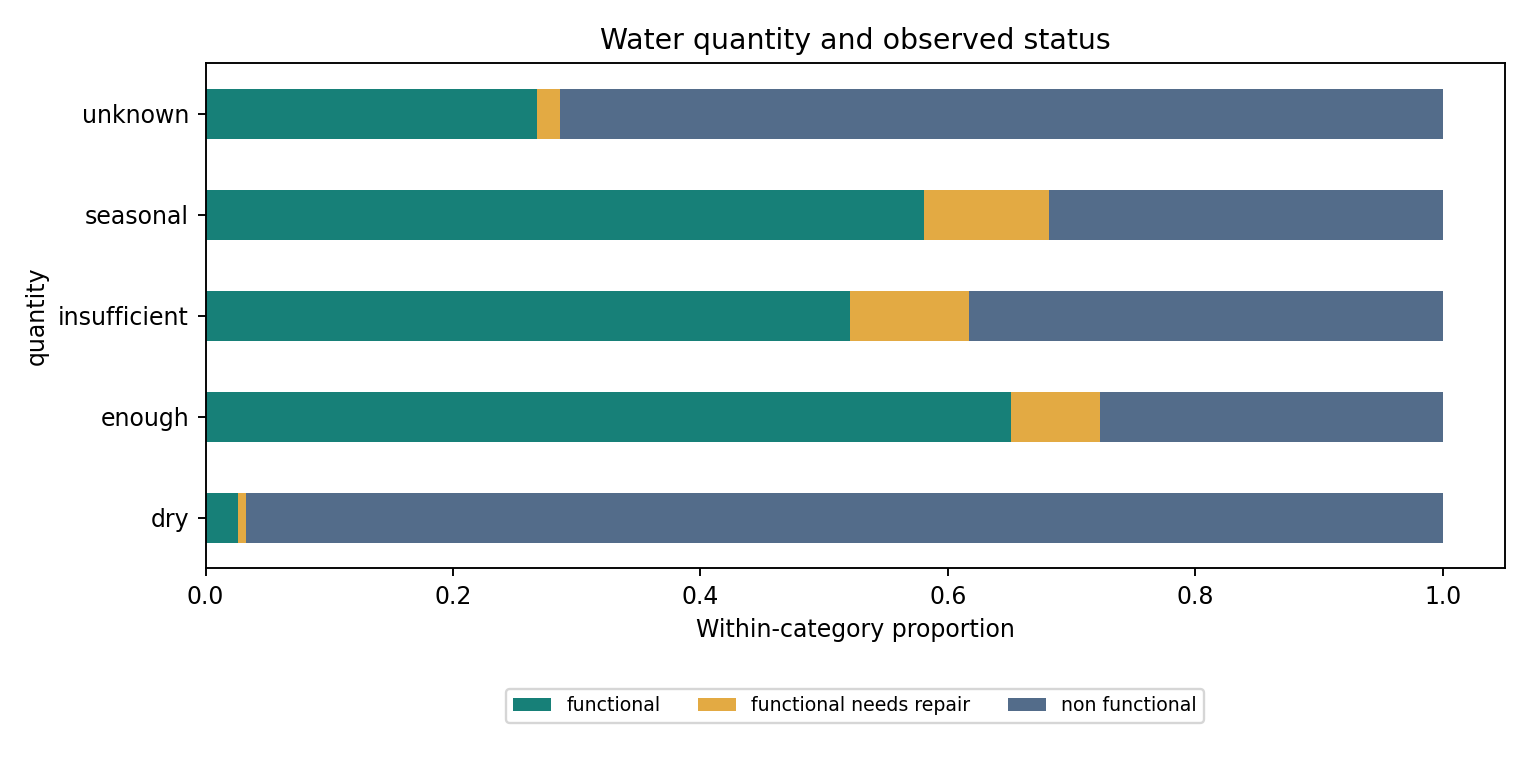

该图描述相关性；不能据此推断水量对故障的因果效应。


In [4]:
eda = X_train.copy()
eda['status_group'] = y_train.to_numpy()
quantity = pd.crosstab(eda.quantity, eda.status_group).reindex(columns=LABELS, fill_value=0)
quantity.to_csv(OUT / 'quantity_by_status.csv')
quantity.div(quantity.sum(axis=1), axis=0).plot.barh(
    stacked=True, figsize=(9, 4.5), color=['#178078', '#e3aa43', '#536c8a'])
plt.xlabel('Within-category proportion'); plt.title('Water quantity and observed status')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / 'quantity_status.png', dpi=170); plt.close()
display(Image(filename=str(FIG / 'quantity_status.png')))
print('该图描述相关性；不能据此推断水量对故障的因果效应。')

## 3. 特征工程与预处理

`PumpFeatures` 仅逐行处理，不计算整体统计量，也不读取目标变量：

1. 去掉 `id`、名称类高基数字段和预先选定的重复层级字段，减少复杂度；不宣称这套删除方案最优。
2. `construction_year<=0` 或晚于记录年份时设为缺失；构造“记录年份 - 建造年份”的泵龄。
3. 经纬度绝对值小于 0.1 作为本数据中的无效坐标标记处理；海拔为 0 仍保留。
4. `population`、`amount_tsh` 的零值保留，增加零值标记及 `log1p` 特征。
5. 地区代码按类别处理，并组合地区与区县代码，避免区县代码跨地区复用。
6. 类别去首尾空格、统一小写，缺失记为 `__missing__`。

Logistic Regression 和 Random Forest 的中位数填补、数值标准化及 One-Hot 编码都放在 Pipeline 中，
在每个交叉验证训练折内重新拟合。低频类别合并规则也只从该训练折学习。
CatBoost 直接接收类别字段和数值缺失值，类别统计由模型在当前训练折内部处理。

In [5]:
features = PumpFeatures().fit_transform(X_train)
print('工程后字段数：', features.shape[1])
display(features[['construction_year', 'pump_age', 'recorded_year', 'recorded_month',
                  'population', 'population_is_zero', 'log1p_population']].head(6))
models = build_models(X_train, threads=4)
for name, model in models.items():
    print(name, '=>', model.named_steps['model'].__class__.__name__)

工程后字段数： 35


,construction_year,pump_age,recorded_year,recorded_month,population,population_is_zero,log1p_population
43360,NaN,NaN,2011.0,7.0,0,1.0,0.000000
7263,2008.0,3.0,2011.0,3.0,175,0.0,5.170484
2486,2010.0,1.0,2011.0,3.0,2300,0.0,7.741099
313,NaN,NaN,2011.0,7.0,0,1.0,0.000000
52726,NaN,NaN,2011.0,3.0,0,1.0,0.000000
8558,1986.0,25.0,2011.0,8.0,200,0.0,5.303305


majority => DummyClassifier
logistic => LogisticRegression
random_forest => RandomForestClassifier
catboost_depth6 => CatBoostClassifier
catboost_depth8 => CatBoostClassifier


## 4. 实验设计与实际训练

候选模型为多数类基线、逻辑回归、240 棵树的随机森林，以及深度 6/8 的两组 CatBoost。
CatBoost 分别训练 650/850 轮，学习率固定为 0.07，不使用最终验证集进行早停。
三折交叉验证按 Accuracy 选择模型；Macro-F1 用作补充诊断。
只使用 CPU，每次最多 4 线程，交叉验证不再套并行任务。

下面默认复用本项目已生成的完整实验结果；在新目录没有结果时会实际运行建模。
若要重新实验，把 `FORCE_RETRAIN` 设为 `True`。不要在查看验证成绩后反复调参再声称验证集独立。

In [6]:
FORCE_RETRAIN = False
required_results = ['run_metadata.json', 'model_comparison.csv', 'validation_predictions.csv',
                    'errors.csv', 'classification_report.json']
if FORCE_RETRAIN or not all((OUT / name).exists() for name in required_results):
    subprocess.run([sys.executable, str(ROOT / 'pump_model.py'), '--threads', '4'], check=True,
                   cwd=str(ROOT))
else:
    print('读取已实际运行的结果；本单元格没有重新训练模型。')
metadata = json.loads((OUT / 'run_metadata.json').read_text())
comparison = pd.read_csv(OUT / 'model_comparison.csv')
print('选择依据：', metadata['selection_rule'])
print('按开发集 CV 选中：', metadata['selected_model'])
display(comparison.round(5))

读取已实际运行的结果；本单元格没有重新训练模型。
选择依据： highest training-only 3-fold CV accuracy
按开发集 CV 选中： catboost_depth8


,model,cv_accuracy_mean,cv_accuracy_std,cv_macro_f1_mean,train_accuracy,validation_accuracy,validation_macro_f1,seconds
0,catboost_depth8,0.80434,0.00300,0.68395,0.87889,0.81086,0.68189,966.86484
1,catboost_depth6,0.80114,0.00168,0.67591,0.87330,0.80513,0.67375,362.45587
2,random_forest,0.79878,0.00178,0.65785,0.86820,0.80471,0.65793,84.25812
3,logistic,0.76303,0.00013,0.62139,0.77835,0.76995,0.62102,26.34906
4,majority,0.54308,0.00004,0.23463,0.54308,0.54310,0.23464,4.31242


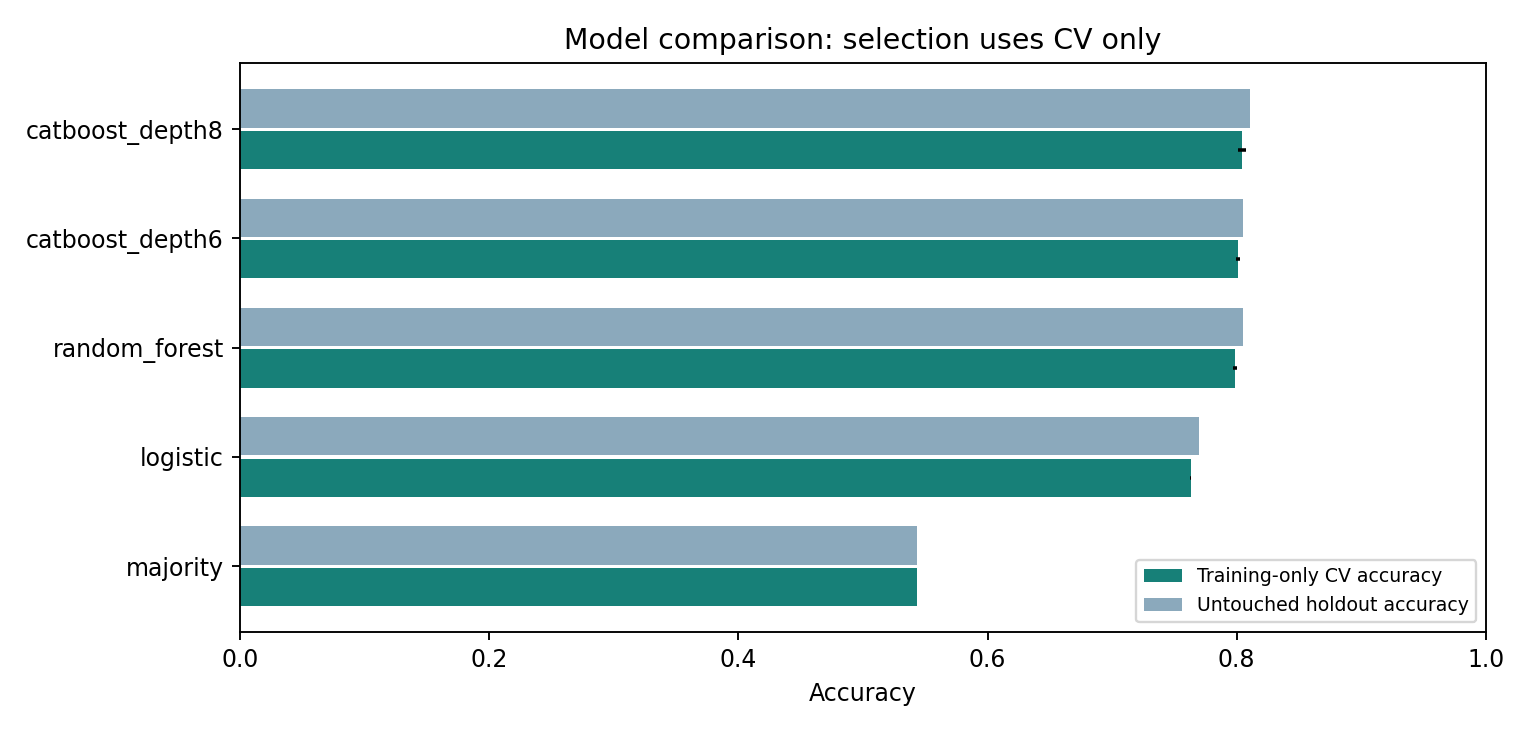

误差棒是 3 折分数的样本标准差，不是置信区间。


In [7]:
view = comparison.sort_values('cv_accuracy_mean')
fig, ax = plt.subplots(figsize=(9, 4.3))
positions = np.arange(len(view))
ax.barh(positions-0.19, view.cv_accuracy_mean, height=0.35,
        xerr=view.cv_accuracy_std, label='Training-only CV accuracy', color='#178078')
ax.barh(positions+0.19, view.validation_accuracy, height=0.35,
        label='Untouched holdout accuracy', color='#8ba9bc')
ax.set_yticks(positions, view.model); ax.set_xlim(0, 1)
ax.set_xlabel('Accuracy'); ax.legend(loc='lower right', fontsize=8)
ax.set_title('Model comparison: selection uses CV only')
fig.tight_layout(); fig.savefig(FIG / 'model_comparison.png', dpi=170); plt.close(fig)
display(Image(filename=str(FIG / 'model_comparison.png')))
print('误差棒是 3 折分数的样本标准差，不是置信区间。')

## 5. 最终验证、混淆矩阵与错误分析

验证集真实标签只用于报告泛化能力。矩阵行是真实类别，列是预测类别；
应结合需维修类的 Recall 检查模型是否偏向多数类。
下面由逐行验证预测重新计算指标，以核对结果文件的一致性。

独立验证 Accuracy =

 0.8108585858585858
独立验证 Macro-F1 = 0.6818912185475186


,precision,recall,f1-score,support
functional,0.7986,0.9095,0.8504,6452.0000
functional needs repair,0.6040,0.2827,0.3852,863.0000
non functional,0.8530,0.7713,0.8101,4565.0000
accuracy,0.8109,0.8109,0.8109,0.8109
macro avg,0.7518,0.6545,0.6819,11880.0000
weighted avg,0.8053,0.8109,0.8011,11880.0000


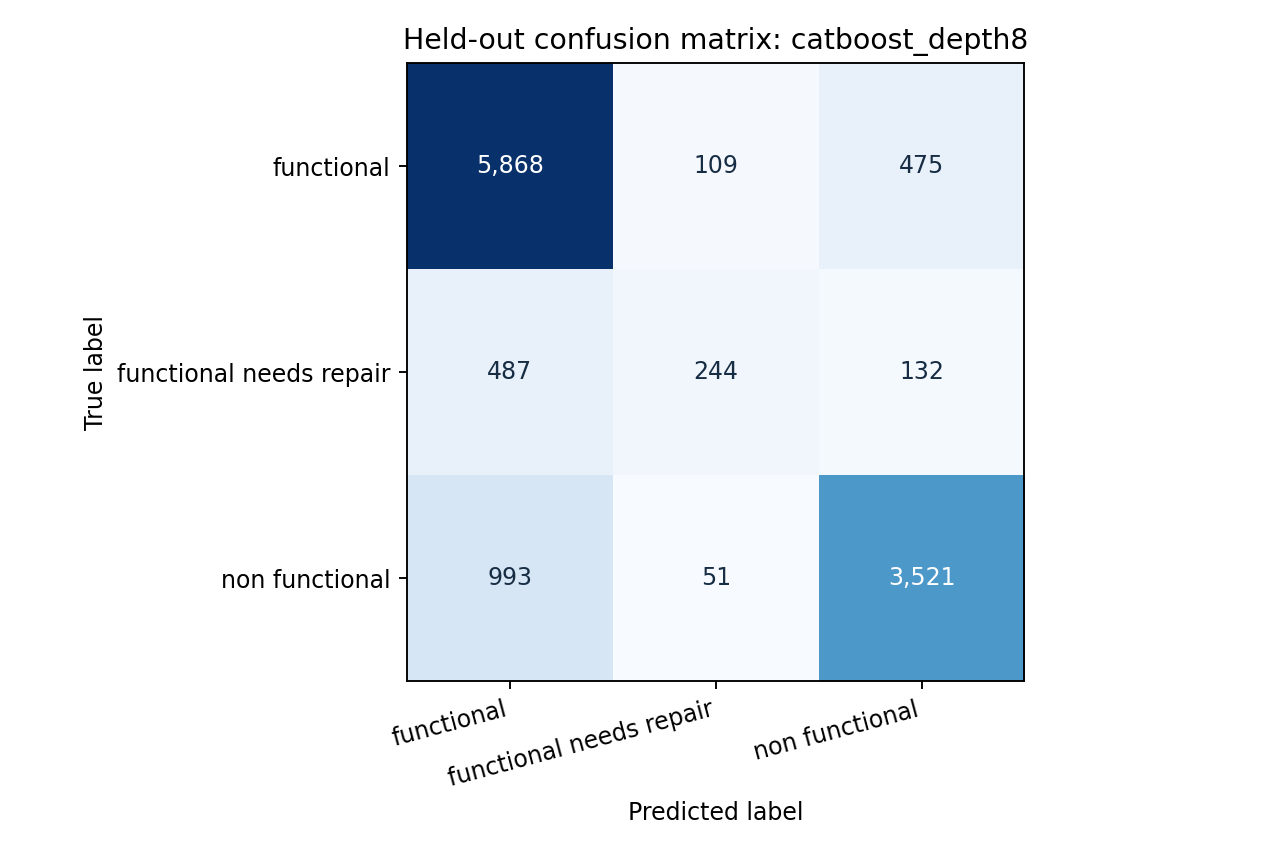

In [8]:
predictions = pd.read_csv(OUT / 'validation_predictions.csv')
report = json.loads((OUT / 'classification_report.json').read_text())
print('独立验证 Accuracy =', accuracy_score(predictions.actual, predictions.prediction))
print('独立验证 Macro-F1 =', f1_score(predictions.actual, predictions.prediction, average='macro'))
display(pd.DataFrame(report).T.round(4))
cm = confusion_matrix(predictions.actual, predictions.prediction, labels=LABELS)
fig, ax = plt.subplots(figsize=(7.5, 5))
image = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(3), LABELS, rotation=15, ha='right')
ax.set_yticks(range(3), LABELS)
ax.set_xlabel('Predicted label'); ax.set_ylabel('True label')
ax.set_title('Held-out confusion matrix: ' + metadata['selected_model'])
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{cm[i,j]:,}', ha='center', va='center',
                color='white' if cm[i,j] > cm.max()/2 else '#172d44')
fig.tight_layout(); fig.savefig(FIG / 'confusion_matrix.png', dpi=170); plt.close(fig)
display(Image(filename=str(FIG / 'confusion_matrix.png')))

In [9]:
errors = pd.read_csv(OUT / 'errors.csv')
print('错误样本数：', len(errors))
display(pd.crosstab(errors.actual, errors.prediction))
display(errors[['id', 'quantity', 'waterpoint_type', 'region', 'actual', 'prediction']].head(10))
print('完整错误样本：results/errors.csv；可进一步按地区、泵龄和水泵类型检查偏差。')

错误样本数： 2247


prediction,functional,functional needs repair,non functional
actual,,,
functional,0,109,475
functional needs repair,487,0,132
non functional,993,51,0


,id,quantity,waterpoint_type,region,actual,prediction
0,19684,enough,hand pump,Mwanza,non functional,functional
1,47818,seasonal,communal standpipe,Tabora,functional needs repair,functional
2,36911,insufficient,communal standpipe,Arusha,functional needs repair,functional
3,69121,enough,hand pump,Tabora,non functional,functional
4,48279,insufficient,communal standpipe,Pwani,functional,non functional
5,26911,enough,hand pump,Shinyanga,non functional,functional
6,41256,insufficient,communal standpipe,Kilimanjaro,non functional,functional
7,14380,enough,communal standpipe,Iringa,non functional,functional
8,2665,insufficient,hand pump,Kagera,functional,non functional
9,29412,insufficient,communal standpipe multiple,Kilimanjaro,non functional,functional


完整错误样本：results/errors.csv；可进一步按地区、泵龄和水泵类型检查偏差。


,feature,importance
0,ward,12.093444
1,quantity,9.367131
2,extraction_type,6.535044
3,funder,6.006827
4,lga,5.671050
5,waterpoint_type,5.245146
6,source,5.129284
7,payment,4.916733
8,district_key,4.802816
9,subvillage,3.672112


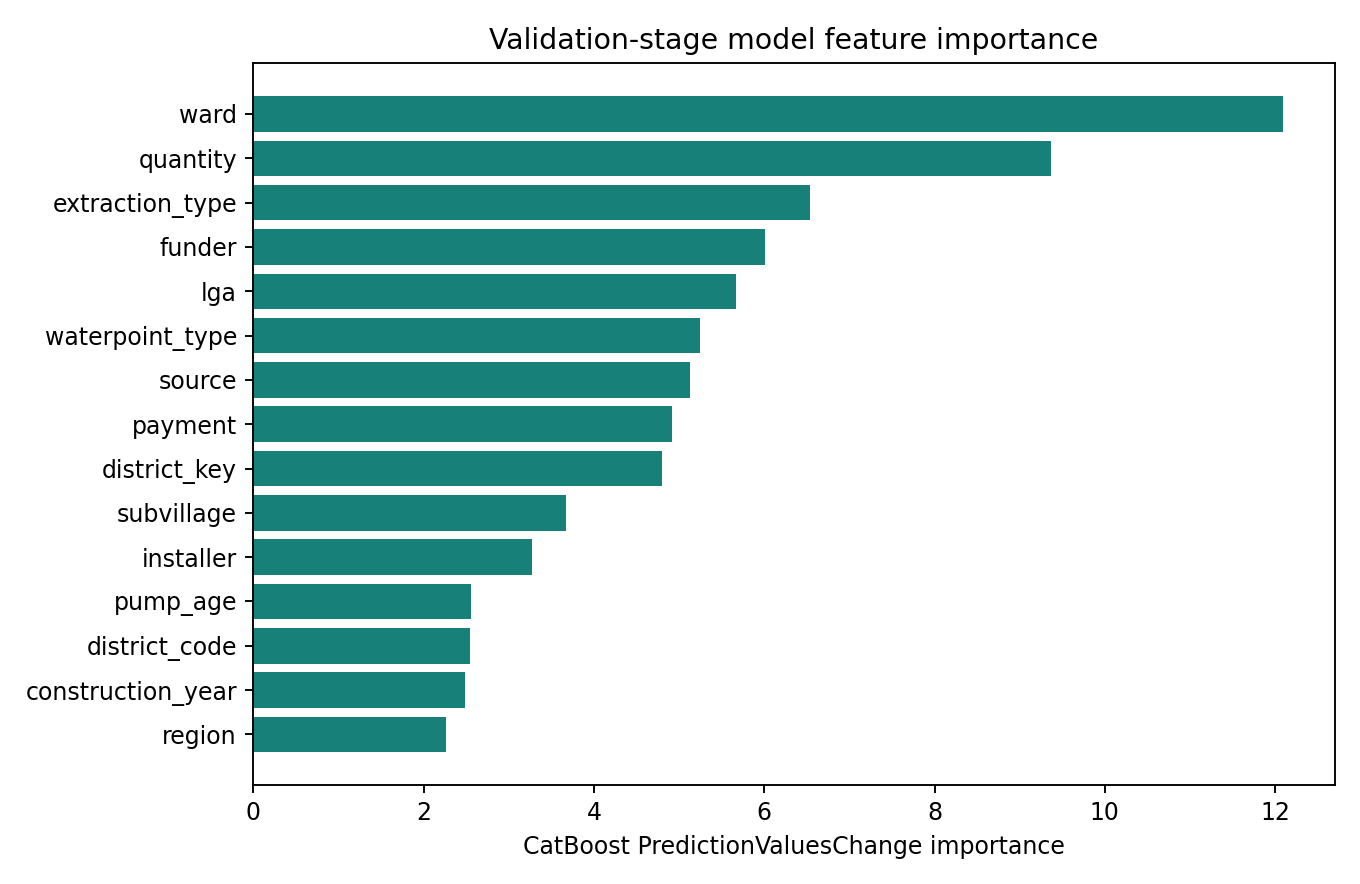

该重要性来自开发集模型，反映模型关联；不代表因果或维修收益。


In [10]:
importance_path = OUT / 'feature_importance.csv'
if importance_path.exists():
    importance = pd.read_csv(importance_path)
    display(importance.head(15))
    top = importance.head(15).sort_values('importance')
    fig, ax = plt.subplots(figsize=(8, 5.2))
    ax.barh(top.feature, top.importance, color='#178078')
    ax.set_xlabel('CatBoost PredictionValuesChange importance')
    ax.set_title('Validation-stage model feature importance')
    fig.tight_layout(); fig.savefig(FIG / 'feature_importance.png', dpi=170); plt.close(fig)
    display(Image(filename=str(FIG / 'feature_importance.png')))
    print('该重要性来自开发集模型，反映模型关联；不代表因果或维修收益。')
else:
    print('本次最佳模型不是 CatBoost，未导出该模型专属的重要性。')

## 6. 全量重训与提交文件

选定参数后，脚本在全部带标签样本上重训，预测无标签测试集。
最终模型已使用原验证集，因此此时不能再用那个验证集给它声称“独立”的分数。

提交文件只有 `id,status_group` 两列，保留原始测试 ID 的顺序。
本例使用 DrivenData 官方代码仓库发布的 `SubmissionFormat.csv`，其全部 ID 和顺序已与测试集核对。
脚本按模板中的 ID 重新对齐预测；即使输入测试特征顺序改变，也可保持正确对应。
没有上传至 DrivenData，线上成绩留空。

In [11]:
submission = pd.read_csv(OUT / 'submission.csv')
assert submission.columns.tolist() == ['id', 'status_group']
assert len(submission) == len(X_test) and submission.id.is_unique
official_template = pd.read_csv(ROOT / 'data/raw/SubmissionFormat.csv')
assert submission.id.tolist() == official_template.id.tolist()
assert not submission.isna().any().any()
assert set(submission.status_group) <= set(LABELS)
print('格式检查通过：', submission.shape)
display(submission.head(10))
print('线上成绩：', metadata['online_score'])
print('SHA-256：', metadata['submission_sha256'])

格式检查通过： (14850, 2)


,id,status_group
0,50785,functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional
5,52449,functional
6,24806,functional
7,28965,non functional
8,36301,non functional
9,54122,functional


线上成绩： None
SHA-256： d1a9a1f19c7de8a63aeb39a8655e53091adab96b3a3c8588d38015f9e1c0302e


## 7. 讨论与可扩展实验

- **类别不均衡：**需维修类少，Accuracy 可能掩盖低 Recall；可在新的训练内部验证中比较类权重，
  但 class weight 不保证同时提升总体准确率，需明确取舍。
- **地理相关性：**随机分层验证可能受同地区水泵相似性的影响。若研究跨地区部署，
  应另做按 `region` 或地理网格分组验证；本样例尚未测量这一能力。
- **特征与预算：**名称列删除、低频阈值、深度和轮数是教学用的有限设计；
  当前模型比较不是大规模等预算调参，不能得出某算法普遍更优的结论。
- **数据时效：**这是历史横截面状态分类，不能直接声称预测未来故障时间。
- **可重复性：**固定种子、依赖版本、原始文件校验和、切分 ID、每折分数、逐行预测均已保存。
  不同系统与数值库可能产生细微数值差异。

参考来源：
1. [DrivenData 题目、字段与提交说明](https://www.drivendata.org/competitions/7/pump-it-up-data-mining-the-water-table/page/25/)
2. [官方课程项目使用说明](https://community.drivendata.org/t/use-the-dataset-for-a-class-project/5836)
3. [scikit-learn：防止数据泄漏](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)
4. [CatBoost：类别特征](https://catboost.ai/en/docs/features/categorical-features)
5. [DrivenData 平台论文](https://arxiv.org/abs/1606.07781)
6. [DrivenData 官方仓库提交模板](https://github.com/drivendataorg/pump-it-up/blob/master/data/submission_format.csv)